# MongoDB Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["64.131.114.155"]
server_local_ips = {}
client_ips = ["64.131.114.143", "64.131.114.145", "64.131.114.146", "64.131.114.147",
              "64.131.114.148", "64.131.114.152", "64.131.114.153", "64.131.114.154"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]

## Initialize environment

In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages
allGroup.run("sudo apt update && sudo apt upgrade -y", hide=True)
allGroup.run("sudo reboot", disown=True)
allGroup.close()    

Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True)

## Benchmark server (MongoDB)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/MongoDB/initMongoDBServer.sh")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initMongoDBServer.sh {SERVER_WORKING_DIR} true", hide=True)

## Benchmark client (XBench)
Prepare benchmark client

In [7]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [8]:
targetThreads = [1, 2, 4, 8]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [9]:
runWorkload("INSERT_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760172316
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760172264 | Delta: 52
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760172491
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760172437 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760172672
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760172618 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760172923
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760172809 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760172817 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

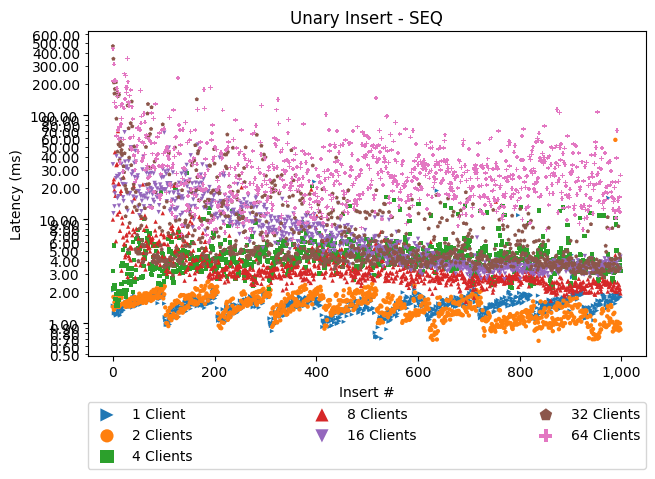

In [10]:
unaryPlots("INSERT_UNARY_SEQ", "MongoDB", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [11]:
runWorkload("INSERT_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760174343
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760174289 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760174519
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760174464 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760174700
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760174645 | Delta: 55
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760174951
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760174837 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760174843 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

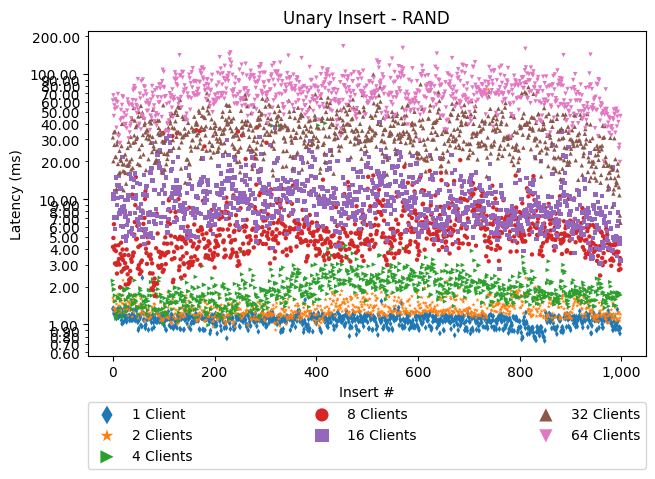

In [12]:
unaryPlots("INSERT_UNARY_RAND", "MongoDB", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [13]:
runWorkload("INSERT_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760176362
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760176308 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760176537
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760176484 | Delta: 53
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760176718
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760176664 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760176970
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760176856 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760176863 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

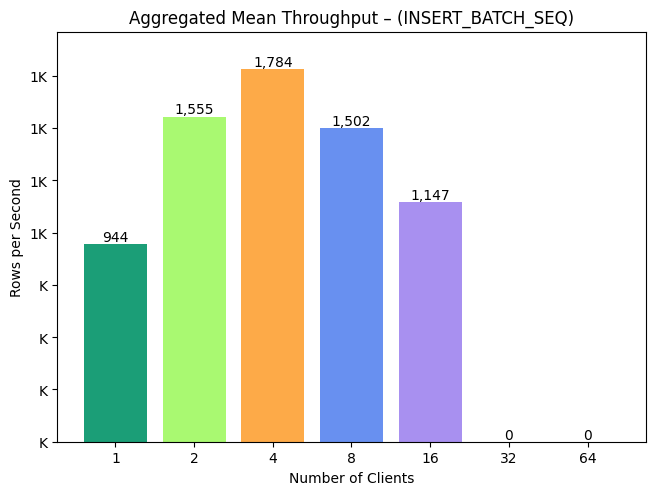

In [14]:
batchPlots("INSERT_BATCH_SEQ", "MongoDB", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [15]:
runWorkload("INSERT_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760179011
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760178958 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760179207
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760179154 | Delta: 53
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760179543
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760179490 | Delta: 53
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760179867
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760179754 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760179761 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

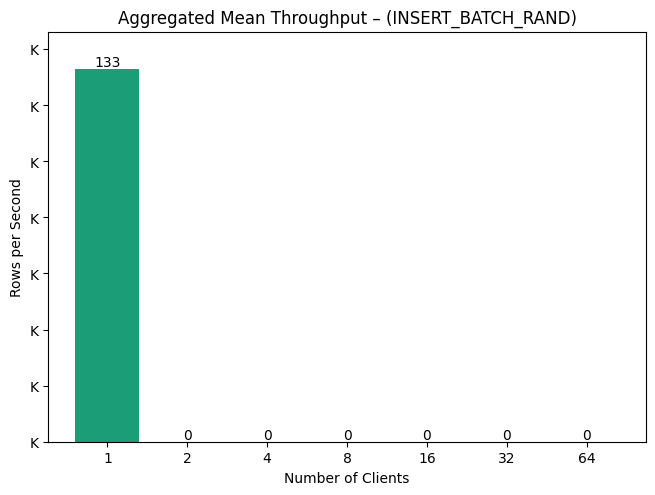

In [16]:
batchPlots("INSERT_BATCH_RAND", "MongoDB", targetThreads, client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [17]:
allGroup.run("sudo reboot", disown=True)
allGroup.close()

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [18]:
serverGroup.put("../scripts/restoreDB.sh")

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT MongoDB BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup)

## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [19]:
runWorkload("QUERY_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760188170
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760188117 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760188344
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760188290 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760188523
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760188469 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760188774
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760188659 | Delta: 115
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760188666 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

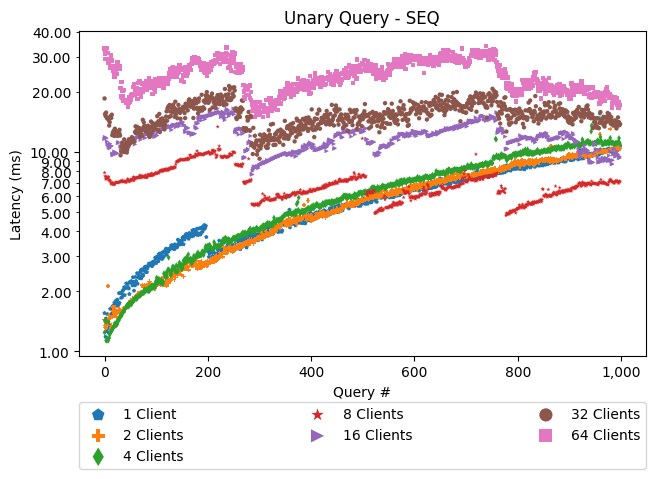

In [20]:
unaryPlots("QUERY_UNARY_SEQ", "MongoDB", targetThreads, client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [21]:
runWorkload("QUERY_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760190151
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760190097 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760190326
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760190272 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760190508
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760190453 | Delta: 55
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760190763
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760190649 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760190655 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

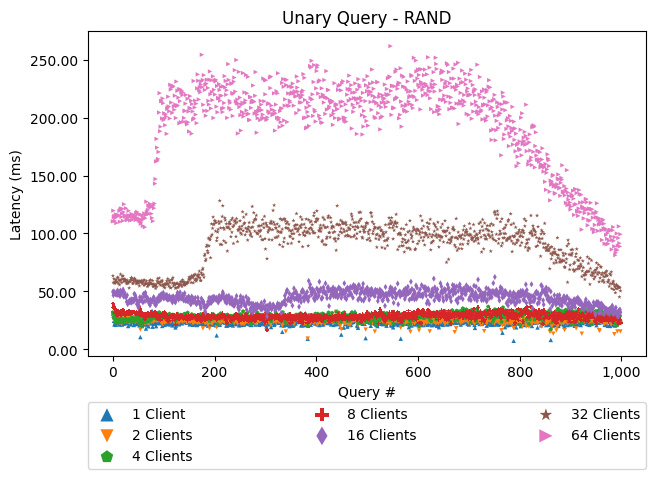

In [22]:
unaryPlots("QUERY_UNARY_RAND", "MongoDB", targetThreads, client_ips, "Query")

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [23]:
runWorkload("QUERY_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760308549
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760308496 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760308724
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760308669 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760308904
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760308850 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760309155
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760309041 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760309048 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

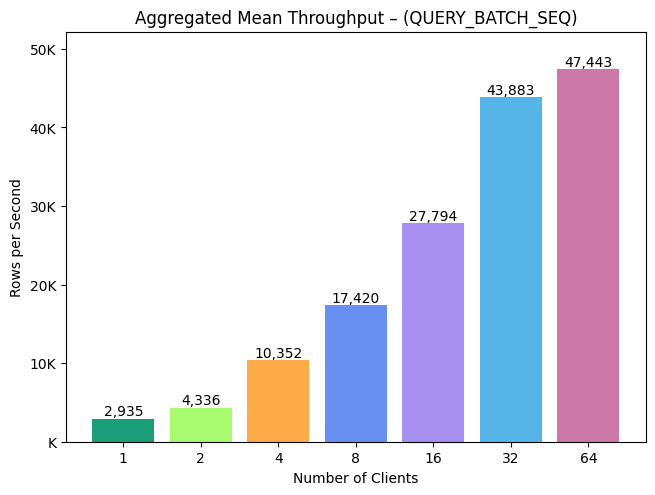

In [24]:
batchPlots("QUERY_BATCH_SEQ", "MongoDB", targetThreads, client_ips, 100)

## Experiment – BATCH QUERY (RAND)

**Perform experiments**

In [25]:
runWorkload("QUERY_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1760310535
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1760310481 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1760310711
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1760310656 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1760310893
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1760310839 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1760311146
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1760311032 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1760311038 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

**Visualization**

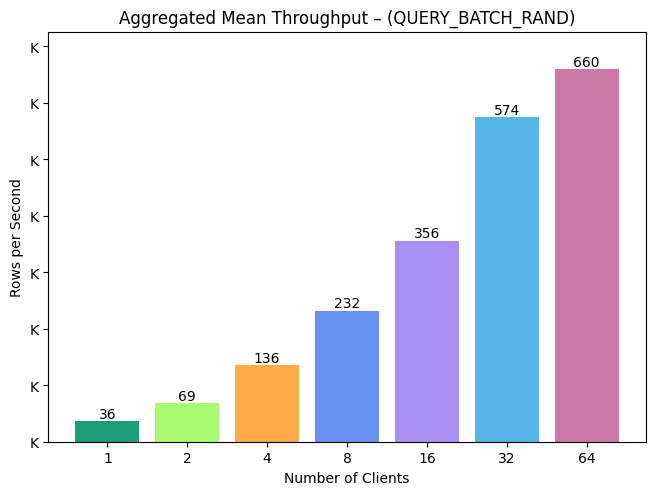

In [26]:
batchPlots("QUERY_BATCH_RAND", "MongoDB", targetThreads, client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [27]:
allGroup.run("sudo reboot", disown=True)
allGroup.close()

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [28]:
runWorkload("AGG_MIN_QUERY", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763250692
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763250638 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763250868
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763250813 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763251051
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763250997 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763251307
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763251193 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763251200 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

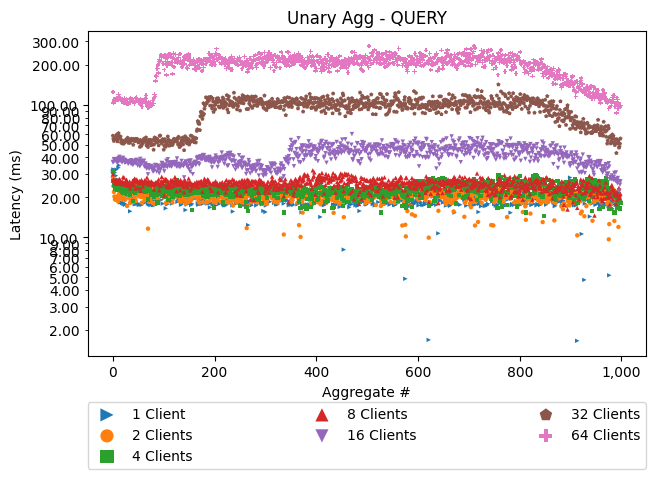

In [29]:
unaryPlots("AGG_MIN_QUERY", "MongoDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [30]:
runWorkload("AGG_MAX_QUERY", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763252955
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763252901 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763253132
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763253077 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763253315
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763253261 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763253572
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763253458 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763253464 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

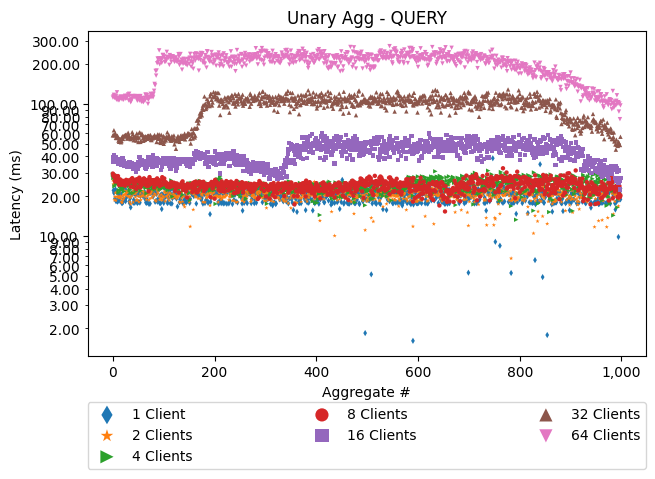

In [31]:
unaryPlots("AGG_MAX_QUERY", "MongoDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [32]:
runWorkload("AGG_SUM_QUERY", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763255229
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763255175 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763255405
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763255351 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763255588
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763255534 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763255844
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763255730 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763255737 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

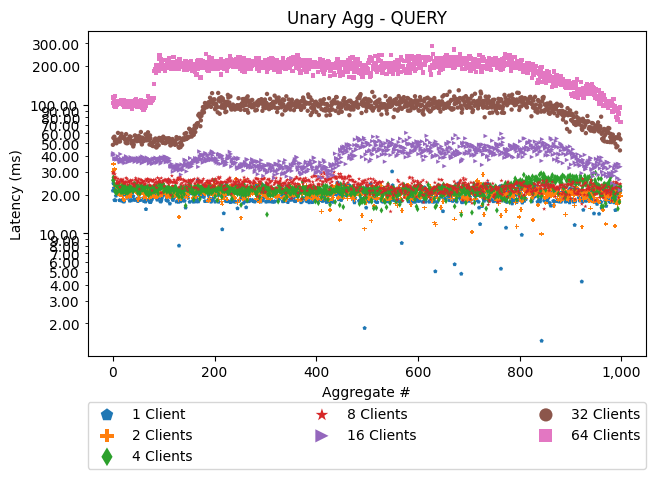

In [33]:
unaryPlots("AGG_SUM_QUERY", "MongoDB", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [34]:
runWorkload("AGG_AVG_QUERY", targetThreads, server_local_ips[server_ips[0]], 9491, "MongoDB", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1763257495
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1763257442 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1763257672
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1763257618 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1763257855
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1763257801 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1763258111
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1763257997 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1763258003 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 176

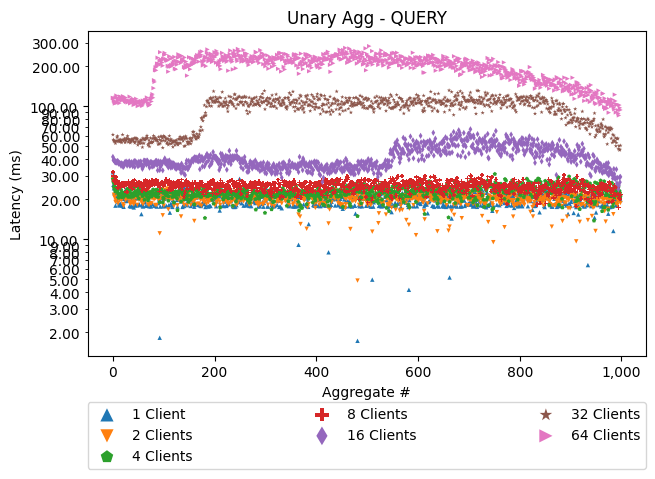

In [35]:
unaryPlots("AGG_AVG_QUERY", "MongoDB", targetThreads, client_ips, "Aggregate", logScale=True)